Nominal amplitude: 6.72 bpm | 63% at 57.6 s | 95% at 172.8 s
95% CI of final amplitude: 6.08–7.39 bpm
Delay L = 45.0 s: max gap = 3.64 bpm, 63% seen at 102.6 s


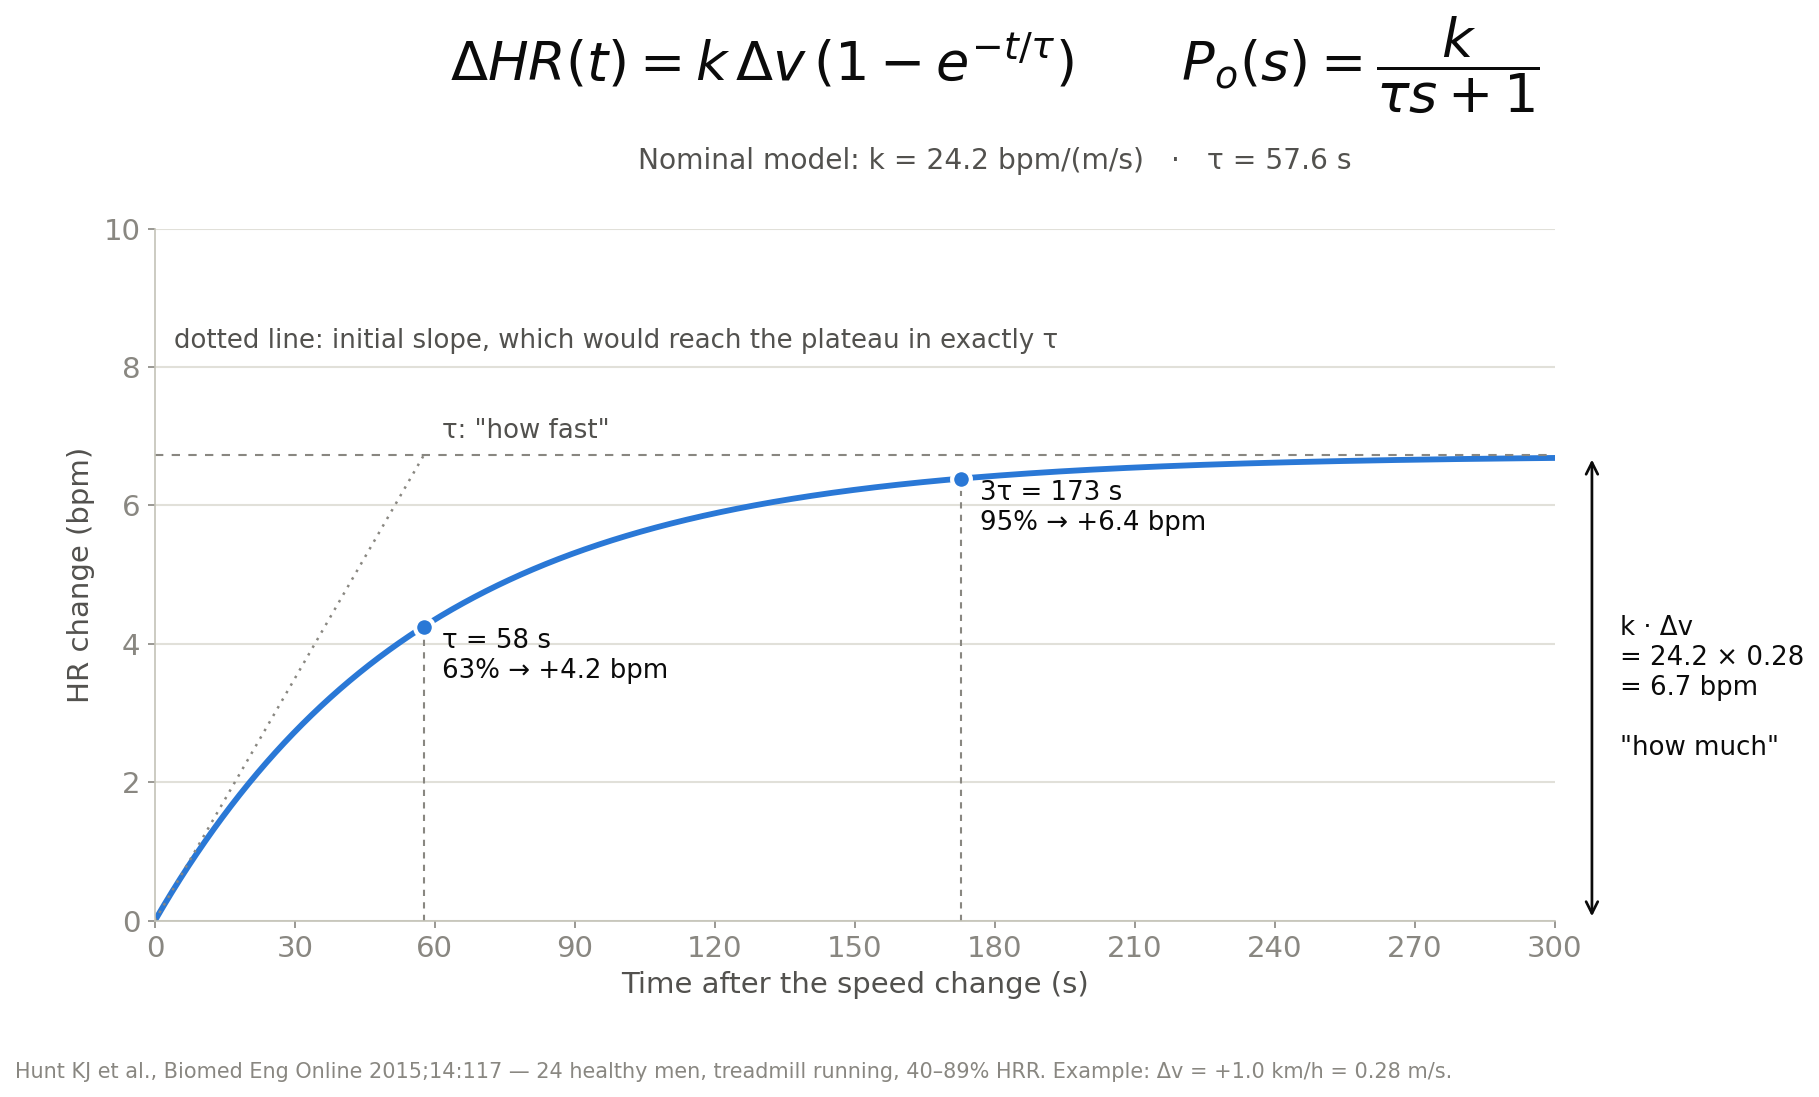

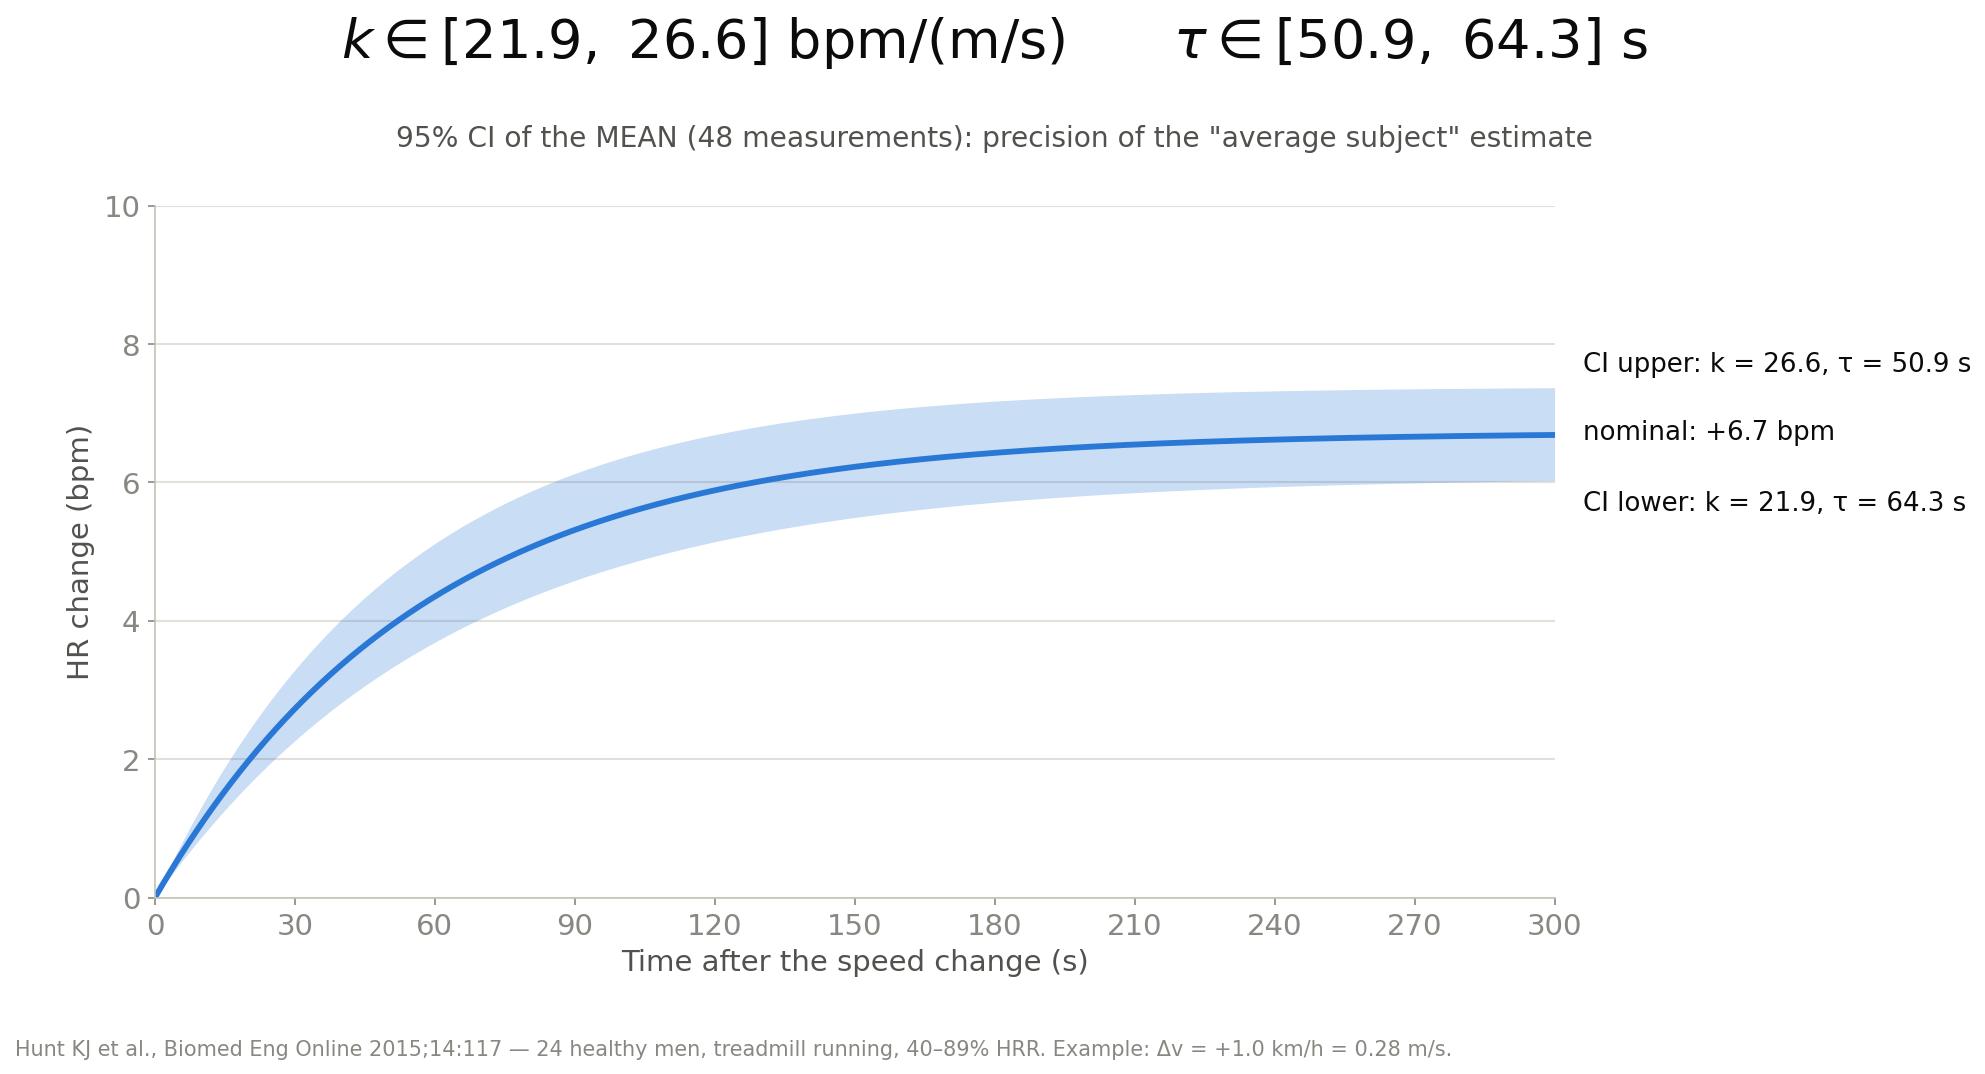

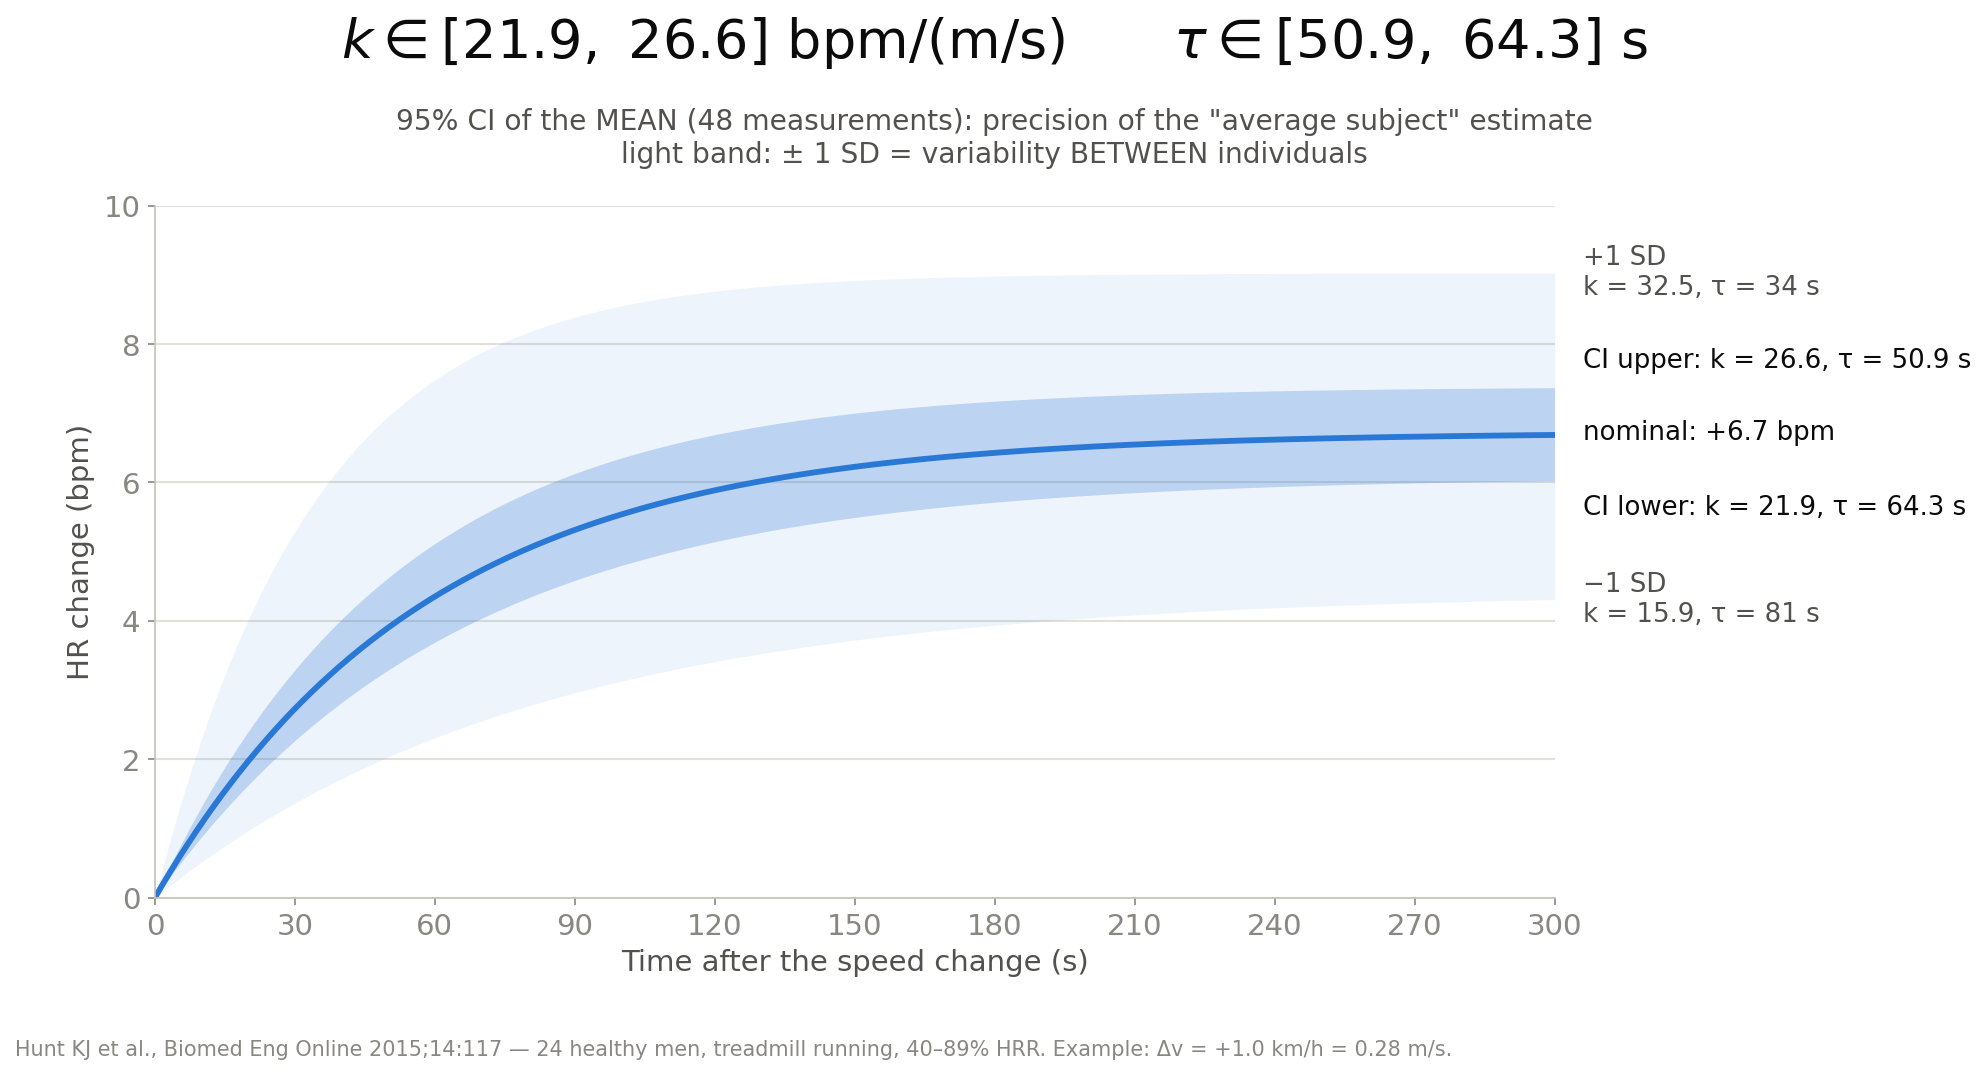

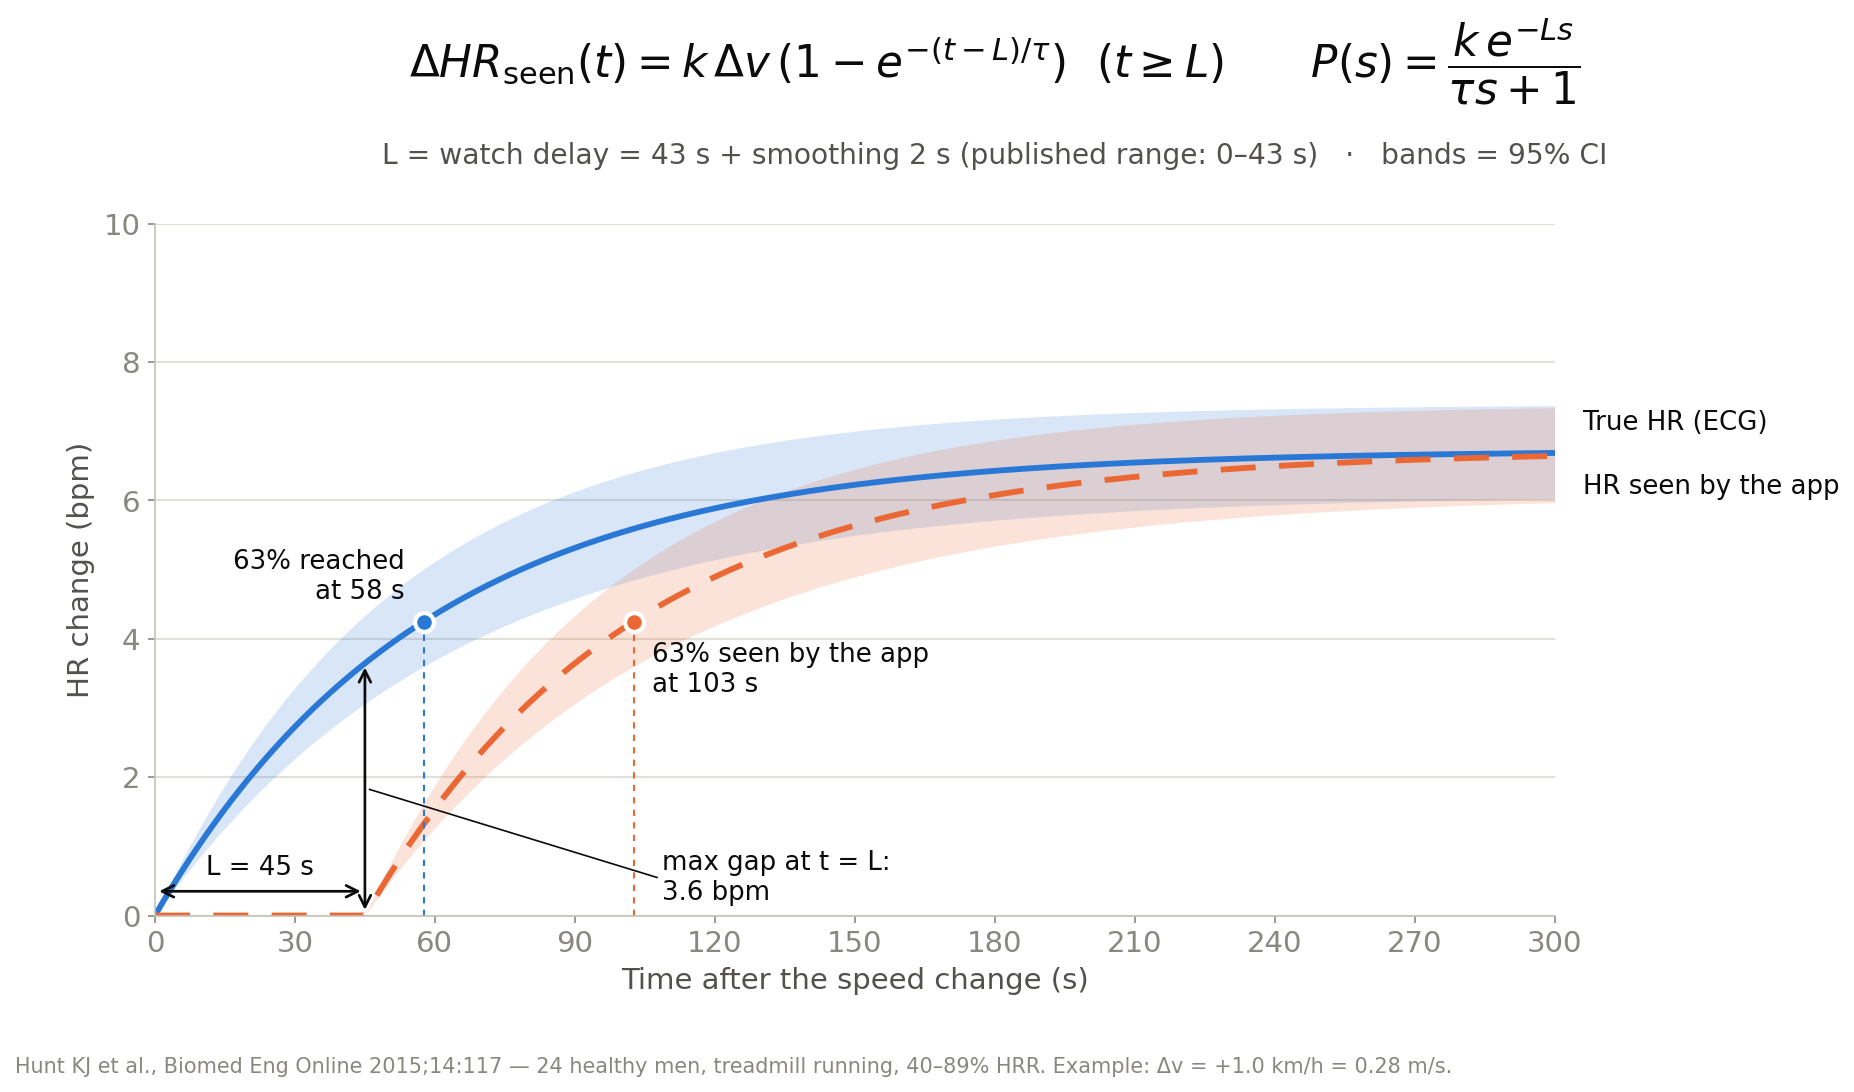

In [11]:
"""
Step-by-step build of the Hunt et al. (2015) heart-rate model, Biomed Eng Online 14:117
One image per step, identical axes, so they can be stacked on a slide:
  1. nominal model with k and τ
  2. model with the 95 % confidence interval of k and τ
  2b. (optional) same + between-subject variability (± 1 SD)
  3. model with the watch delay

Time domain    : ΔHR(t) = k·Δv·(1 − e^(−t/τ))
Laplace domain : P(s) = k / (τs + 1)        ; with delay L : P(s) = k·e^(−Ls) / (τs + 1)
"""
import numpy as np
import matplotlib.pyplot as plt

# ============================ editable parameters ============================
K, TAU = 24.2, 57.6                        # overall nominal model (Hunt, eq. 2)
K_CI, TAU_CI = (21.9, 26.6), (50.9, 64.3)  # 95 % CI of the mean (48 measurements)
K_SD, TAU_SD = 8.3, 23.6                   # standard deviations (between-subject variability)
DV_KMH = 1.0                               # speed change studied (km/h)
WATCH_DELAY = 43.0                         # s, published range 0–43 s (Bent 2020)
SMOOTHING_DELAY = 2.0                      # s, set to 2.0 to add the 5-point moving average at 1 Hz
T_MAX = 300                                # s shown
# =============================================================================

KMH = 3.6
DV = DV_KMH / KMH                          # m/s
L = WATCH_DELAY + SMOOTHING_DELAY
A = K * DV                                 # nominal final amplitude (bpm)

BLUE, ORANGE, INK, INK2, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({"font.size": 14, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,
                     "xtick.color": MUTED, "ytick.color": MUTED, "mathtext.fontset": "dejavusans"})
t = np.linspace(0, T_MAX, 3001)
Y_MAX = 10.0


def resp(t, k, tau, delay=0.0):
    """First-order step response, with optional pure delay."""
    tt = np.clip(t - delay, 0, None)
    return k * DV * (1 - np.exp(-tt / tau))


def num(x, d=1):
    return f"{x:.{d}f}"


def new_figure(equation, subtitle, eq_size=26):
    fig = plt.figure(figsize=(13.33, 7.5), dpi=150)
    fig.patch.set_facecolor("white")
    fig.text(0.5, 0.915, equation, ha="center", va="center", fontsize=eq_size, color=INK)
    fig.text(0.5, 0.83, subtitle, ha="center", va="center", fontsize=13.5, color=INK2)
    ax = fig.add_axes([0.08, 0.155, 0.70, 0.615])
    ax.set_xlim(0, T_MAX); ax.set_ylim(0, Y_MAX)
    ax.set_xticks(range(0, T_MAX + 1, 30)); ax.set_yticks(range(0, int(Y_MAX) + 1, 2))
    ax.grid(axis="y", color=GRID, lw=1); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.set_xlabel("Time after the speed change (s)")
    ax.set_ylabel("HR change (bpm)")
    fig.text(0.01, 0.015, f"Hunt KJ et al., Biomed Eng Online 2015;14:117 — 24 healthy men, treadmill running, "
             f"40–89% HRR. Example: Δv = +{num(DV_KMH)} km/h = {num(DV, 2)} m/s.", fontsize=10, color=MUTED)
    return fig, ax


def label(ax, x, y, text, **kw):
    kw.setdefault("color", INK)
    ax.text(x, y, text, fontsize=12.5, clip_on=False, **kw)


# ---------------------------------------------------------------- 1. k and τ
fig, ax = new_figure(
    r"$\Delta HR(t) = k\,\Delta v\,\left(1 - e^{-t/\tau}\right)$"
    r"$\qquad P_o(s) = \dfrac{k}{\tau s + 1}$",
    f"Nominal model: k = {num(K)} bpm/(m/s)   ·   τ = {num(TAU)} s")
ax.plot(t, resp(t, K, TAU), color=BLUE, lw=2.8)
ax.axhline(A, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.plot([0, TAU], [0, A], color=MUTED, lw=1.2, ls=(0, (1, 2.5)))            # tangent at the origin
label(ax, 4, A + 1.55, "dotted line: initial slope, which would reach the plateau in exactly τ", color=INK2)
for n, pct in [(1, 63), (3, 95)]:
    x, y = n * TAU, A * (1 - np.exp(-n))
    ax.plot([x, x], [0, y], color=MUTED, lw=1, ls=(0, (3, 3)))
    ax.plot(x, y, "o", ms=9, color=BLUE, mec="white", mew=2, zorder=5)
    label(ax, x + 4, y - 0.75, f"{'τ' if n == 1 else '3τ'} = {num(x, 0)} s\n{pct}% → +{num(y)} bpm")
ax.annotate("", xy=(T_MAX + 8, A), xytext=(T_MAX + 8, 0), annotation_clip=False,
            arrowprops=dict(arrowstyle="<->", color=INK, lw=1.3))
label(ax, T_MAX + 14, A / 2, f"k · Δv\n= {num(K)} × {num(DV, 2)}\n= {num(A)} bpm\n\n\"how much\"", va="center")
label(ax, TAU + 4, A + 0.25, "τ: \"how fast\"", color=INK2)
fig.savefig("eq1_model_k_tau_en.png", facecolor="white")

# ------------------------------------------------- 2. confidence interval
def band(ax, k_lo, k_hi, tau_lo, tau_hi, delay=0.0, alpha=0.18, colour=BLUE):
    # ΔHR increases with k and decreases with τ: envelope is (low k, high τ) → (high k, low τ)
    lo = resp(t, k_lo, tau_hi, delay)
    hi = resp(t, k_hi, tau_lo, delay)
    ax.fill_between(t, lo, hi, color=colour, alpha=alpha, lw=0)
    return lo, hi

def figure_ci(with_sd):
    eq = (rf"$k \in [{num(K_CI[0])},\ {num(K_CI[1])}]$ bpm/(m/s)"
          rf"$\qquad \tau \in [{num(TAU_CI[0])},\ {num(TAU_CI[1])}]$ s")
    st = "95% CI of the MEAN (48 measurements): precision of the \"average subject\" estimate"
    if with_sd:
        st += "\nlight band: ± 1 SD = variability BETWEEN individuals"
    fig, ax = new_figure(eq, st)
    if with_sd:
        lo, hi = band(ax, K - K_SD, K + K_SD, TAU - TAU_SD, TAU + TAU_SD, alpha=0.08)
        label(ax, T_MAX + 6, hi[-1], f"+1 SD\nk = {num(K + K_SD)}, τ = {num(TAU - TAU_SD, 0)} s", va="center", color=INK2)
        label(ax, T_MAX + 6, lo[-1], f"−1 SD\nk = {num(K - K_SD)}, τ = {num(TAU + TAU_SD, 0)} s", va="center", color=INK2)
    lo, hi = band(ax, K_CI[0], K_CI[1], TAU_CI[0], TAU_CI[1], alpha=0.25)
    ax.plot(t, resp(t, K, TAU), color=BLUE, lw=2.8)
    label(ax, T_MAX + 6, hi[-1] + (0.15 if not with_sd else 0.2), f"CI upper: k = {num(K_CI[1])}, τ = {num(TAU_CI[0])} s", va="bottom")
    label(ax, T_MAX + 6, A, f"nominal: +{num(A)} bpm", va="center")
    label(ax, T_MAX + 6, lo[-1] - (0.15 if not with_sd else 0.2), f"CI lower: k = {num(K_CI[0])}, τ = {num(TAU_CI[1])} s", va="top")
    return fig

figure_ci(False).savefig("eq2_ci95_en.png", facecolor="white")
figure_ci(True).savefig("eq2b_ci95_sd_individuals_en.png", facecolor="white")

# ------------------------------------------------------ 3. watch delay
eq3 = (r"$\Delta HR_{\mathrm{seen}}(t) = k\,\Delta v\,\left(1 - e^{-(t-L)/\tau}\right)\ \ (t \geq L)$"
       r"$\qquad P(s) = \dfrac{k\,e^{-Ls}}{\tau s + 1}$")
st3 = f"L = watch delay = {num(WATCH_DELAY, 0)} s"
if SMOOTHING_DELAY:
    st3 += f" + smoothing {num(SMOOTHING_DELAY, 0)} s"
st3 += " (published range: 0–43 s)   ·   bands = 95% CI"
fig, ax = new_figure(eq3, st3, eq_size=21)
band(ax, K_CI[0], K_CI[1], TAU_CI[0], TAU_CI[1], alpha=0.18)
band(ax, K_CI[0], K_CI[1], TAU_CI[0], TAU_CI[1], delay=L, alpha=0.18, colour=ORANGE)
true_hr, seen_hr = resp(t, K, TAU), resp(t, K, TAU, L)
ax.plot(t, true_hr, color=BLUE, lw=2.8)
ax.plot(t, seen_hr, color=ORANGE, lw=2.8, ls=(0, (6, 4)))
# delay arrow along the axis
ax.annotate("", xy=(L, 0.35), xytext=(0, 0.35), arrowprops=dict(arrowstyle="<->", color=INK, lw=1.3))
label(ax, max(L / 2, 16), 0.5, f"L = {num(L, 0)} s", ha="center", va="bottom")
# maximum gap (at t = L)
gap = A * (1 - np.exp(-L / TAU))
ax.annotate("", xy=(L, gap), xytext=(L, 0.02), arrowprops=dict(arrowstyle="<->", color=INK, lw=1.3))
label(ax, TAU + L + 6, 0.55, f"max gap at t = L:\n{num(gap)} bpm", va="center")
ax.plot([L + 1, TAU + L + 5], [gap * 0.5, 0.55], color=INK, lw=0.8)
# 63 % true vs seen
for x0, y0, c in [(TAU, A * (1 - np.exp(-1)), BLUE), (TAU + L, A * (1 - np.exp(-1)), ORANGE)]:
    ax.plot([x0, x0], [0, y0], color=c, lw=1, ls=(0, (3, 3)))
    ax.plot(x0, y0, "o", ms=9, color=c, mec="white", mew=2, zorder=5)
label(ax, TAU - 4, A * 0.63 + 0.35, f"63% reached\nat {num(TAU, 0)} s", ha="right")
label(ax, TAU + L + 4, A * 0.63 - 1.0, f"63% seen by the app\nat {num(TAU + L, 0)} s")
label(ax, T_MAX + 6, true_hr[-1] + 0.25, "True HR (ECG)", va="bottom")
label(ax, T_MAX + 6, seen_hr[-1] - 0.25, "HR seen by the app", va="top")
fig.savefig("eq3_watch_delay_en.png", facecolor="white")

print(f"Nominal amplitude: {A:.2f} bpm | 63% at {TAU:.1f} s | 95% at {3*TAU:.1f} s")
print(f"95% CI of final amplitude: {K_CI[0]*DV:.2f}–{K_CI[1]*DV:.2f} bpm")
print(f"Delay L = {L:.1f} s: max gap = {gap:.2f} bpm, 63% seen at {TAU+L:.1f} s")

1 km/h speed change while running (Hunt 2015)

                       acceleration +1  deceleration −1
ΔHR at 30 s                     +3.4 bpm         -2.8 bpm
ΔHR at 1 min                    +5.4 bpm         -4.4 bpm
ΔHR at 2 min                    +7.3 bpm         -5.8 bpm
ΔHR at 3 min                    +8.0 bpm         -6.3 bpm
ΔHR at 5 min                    +8.3 bpm         -6.5 bpm
final ΔHR                       +8.4 bpm         -6.6 bpm
initial slope                  8.8 bpm/min        -7.2 bpm/min
63% reached at                    58 s            54 s
95% reached at                   172 s           163 s

Effect of the size of the change (acceleration):
  +0.5 km/h: final ΔHR =   4.2 bpm, initial slope =  4.4 bpm/min, 63% at 58 s (unchanged)
  +1.0 km/h: final ΔHR =   8.4 bpm, initial slope =  8.8 bpm/min, 63% at 58 s (unchanged)
  +1.8 km/h: final ΔHR =  15.1 bpm, initial slope = 15.8 bpm/min, 63% at 58 s (unchanged)
  +2.0 km/h: final ΔHR =  16.8 bpm, initial slope = 17.5

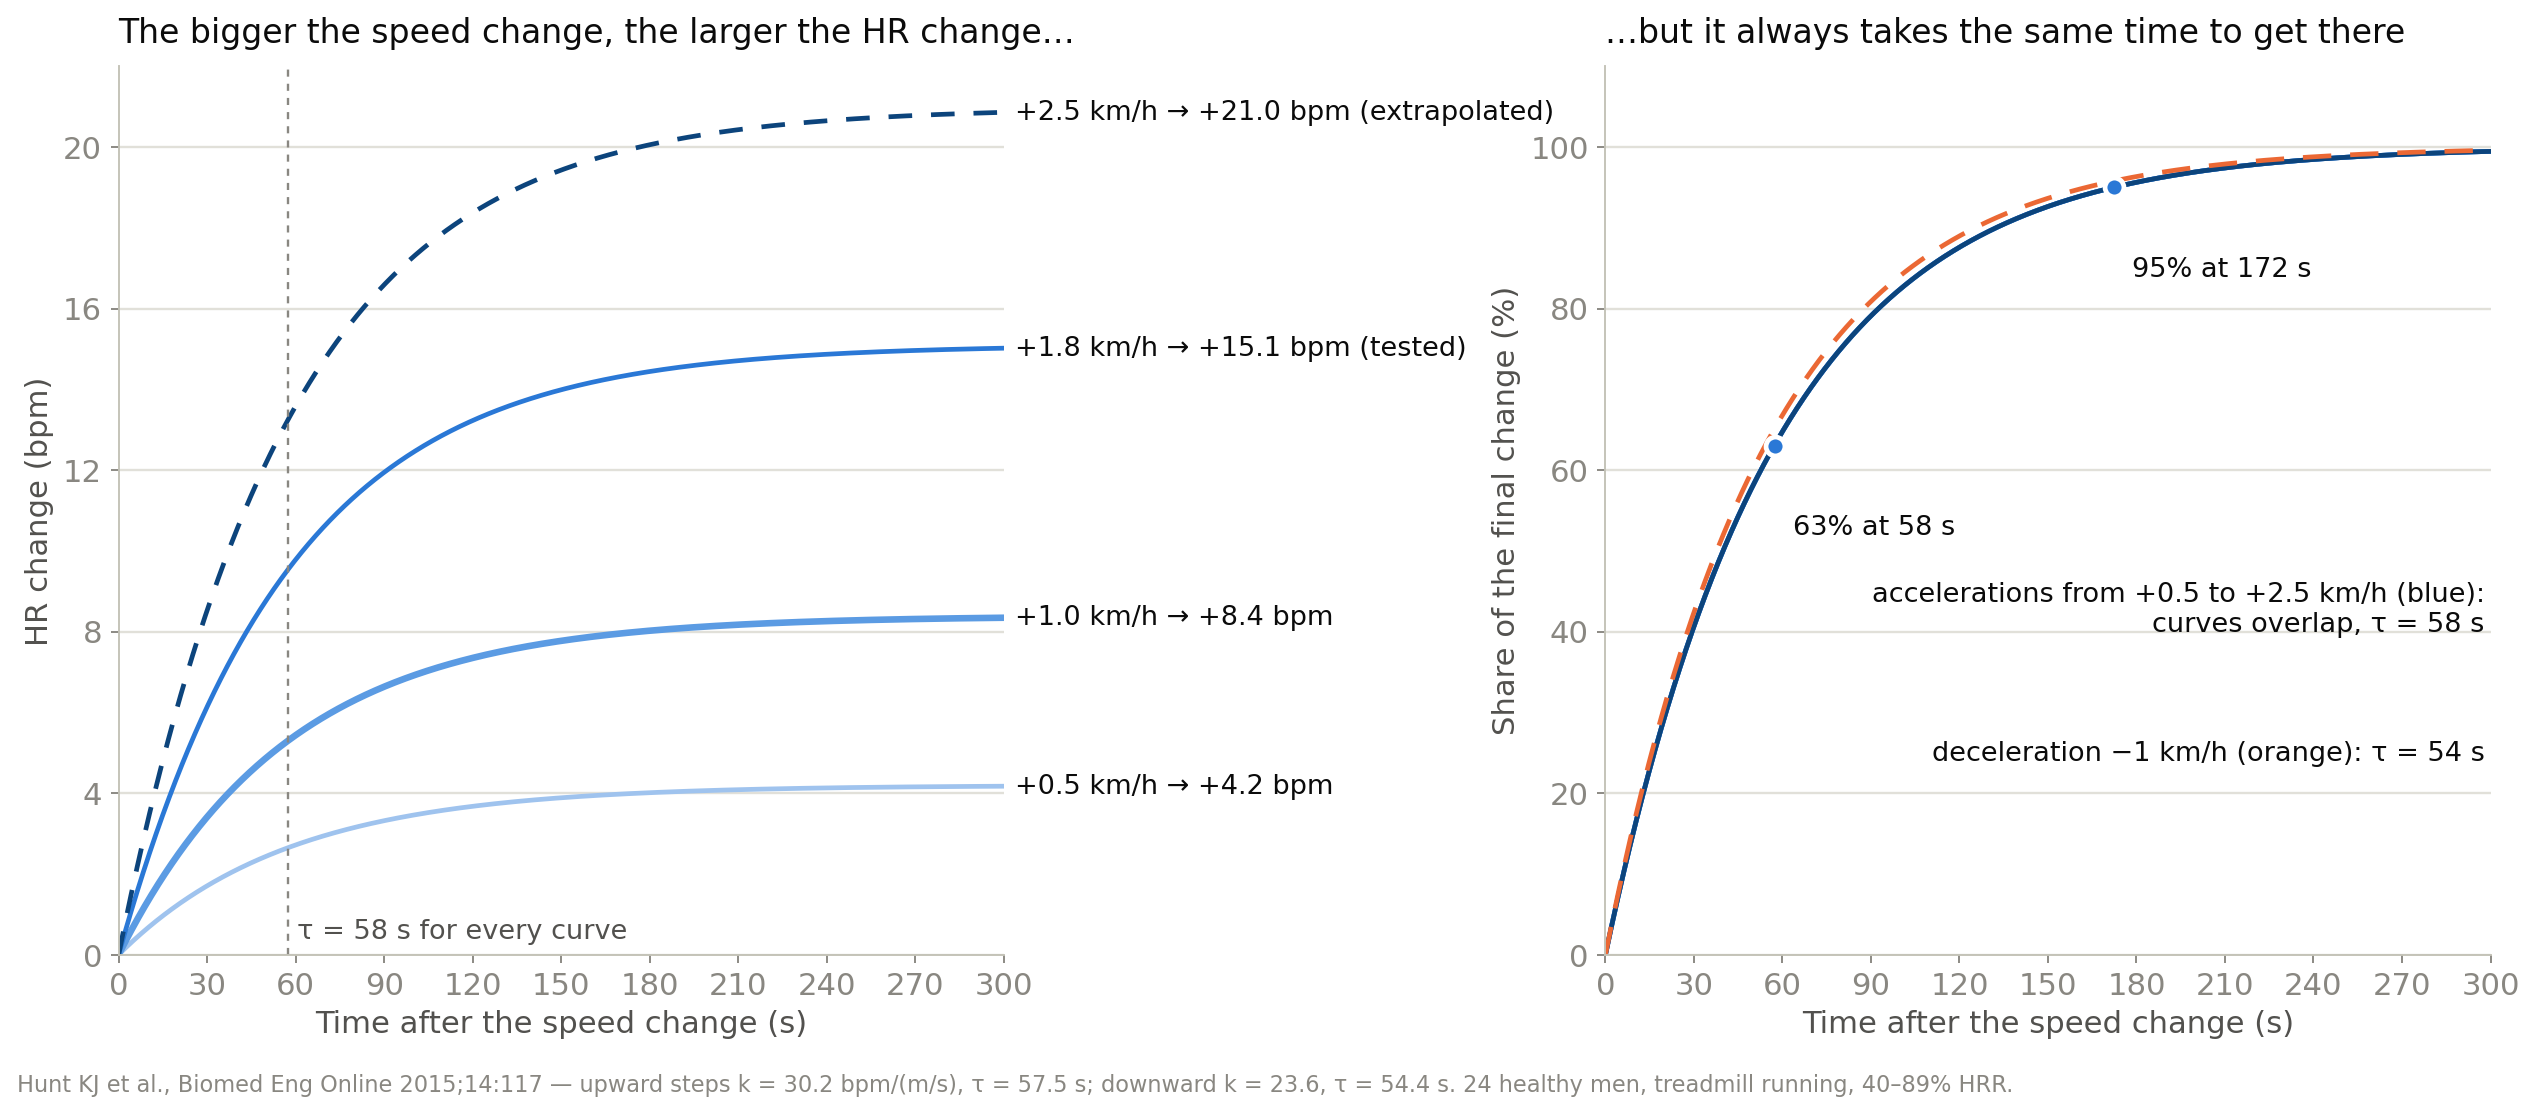

In [12]:
"""
Effect of a 1 km/h speed change on heart-rate kinetics during running
Hunt et al. 2015 model (Biomed Eng Online 14:117), individual steps (p. 9):
  acceleration : k = 30.2 bpm/(m/s), τ = 57.5 s
  deceleration : k = 23.6 bpm/(m/s), τ = 54.4 s   (τ: p = 0.52, n.s.)
Steps tested by Hunt: from v−0.25 to v+0.25 m/s, i.e. Δv = 0.5 m/s = 1.8 km/h.
"""
import numpy as np
import matplotlib.pyplot as plt
 
KMH = 3.6
K_UP, TAU_UP = 30.2, 57.5
K_DN, TAU_DN = 23.6, 54.4
HUNT_STEP = 0.5 * KMH                     # 1.8 km/h
 
def resp(t, k, tau, dv_kmh):
    return k * dv_kmh / KMH * (1 - np.exp(-t / tau))
 
def num(x, d=1):
    return f"{x:.{d}f}"
 
# --------------------------------------------------------------- table
print("1 km/h speed change while running (Hunt 2015)\n")
print(f"{'':22s}{'acceleration +1':>16s}{'deceleration −1':>17s}")
for lab, tt in [("30 s", 30), ("1 min", 60), ("2 min", 120), ("3 min", 180), ("5 min", 300)]:
    print(f"ΔHR at {lab:15s}{resp(tt, K_UP, TAU_UP, 1):>+14.1f} bpm{-resp(tt, K_DN, TAU_DN, 1):>+13.1f} bpm")
print(f"{'final ΔHR':22s}{K_UP/KMH:>+14.1f} bpm{-K_DN/KMH:>+13.1f} bpm")
print(f"{'initial slope':22s}{K_UP/KMH/TAU_UP*60:>12.1f} bpm/min{-K_DN/KMH/TAU_DN*60:>12.1f} bpm/min")
print(f"{'63% reached at':22s}{TAU_UP:>14.0f} s  {TAU_DN:>12.0f} s")
print(f"{'95% reached at':22s}{3*TAU_UP:>14.0f} s  {3*TAU_DN:>12.0f} s")
print("\nEffect of the size of the change (acceleration):")
for dv in [0.5, 1, HUNT_STEP, 2]:
    print(f"  +{dv:.1f} km/h: final ΔHR = {K_UP*dv/KMH:5.1f} bpm, initial slope = "
          f"{K_UP*dv/KMH/TAU_UP*60:4.1f} bpm/min, 63% at {TAU_UP:.0f} s (unchanged)")
 
# --------------------------------------------------------------- figure
BLUE, ORANGE, INK, INK2, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SHADES = ["#9fc3ee", "#5b9be3", "#2a78d6", "#0c447c"]   # one hue, light → dark = small → large Δv
plt.rcParams.update({"font.size": 13, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,
                     "xtick.color": MUTED, "ytick.color": MUTED})
t = np.linspace(0, 300, 3001)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 6.6), dpi=170)
fig.patch.set_facecolor("white")
 
# A: amplitude depends on Δv
for dv, c in zip([0.5, 1.0, HUNT_STEP, 2.5], SHADES):
    y = resp(t, K_UP, TAU_UP, dv)
    ls = "-" if dv <= HUNT_STEP else (0, (5, 4))
    a1.plot(t, y, color=c, lw=2.8 if dv == 1 else 2.0, ls=ls)
    lab = f"+{num(dv)} km/h → +{num(K_UP * dv / KMH)} bpm"
    if abs(dv - HUNT_STEP) < 1e-9:
        lab += " (tested)"
    if dv > HUNT_STEP:
        lab += " (extrapolated)"
    a1.text(304, y[-1], lab, va="center", fontsize=11.5, color=INK, clip_on=False)
a1.axvline(TAU_UP, color=MUTED, lw=1, ls=(0, (3, 3)))
a1.text(TAU_UP + 3, 0.4, "τ = 58 s for every curve", fontsize=11.5, color=INK2)
a1.set_title("The bigger the speed change, the larger the HR change…", loc="left", fontsize=14, color=INK, pad=10)
a1.set_ylabel("HR change (bpm)")
a1.set_ylim(0, 22); a1.set_yticks(range(0, 21, 4))
 
# B: normalised, all curves overlap
for dv, c in zip([0.5, 1.0, HUNT_STEP, 2.5], SHADES):
    a2.plot(t, 100 * resp(t, K_UP, TAU_UP, dv) / (K_UP * dv / KMH), color=c, lw=2.0)
a2.plot(t, 100 * (1 - np.exp(-t / TAU_DN)), color=ORANGE, lw=2.0, ls=(0, (6, 4)))
for n, pct in [(1, 63), (3, 95)]:
    a2.plot(n * TAU_UP, pct, "o", ms=8, color=BLUE, mec="white", mew=2, zorder=5)
    a2.text(n * TAU_UP + 6, pct - 11, f"{pct}% at {num(n * TAU_UP, 0)} s", fontsize=11.5, color=INK)
a2.text(298, 40, "accelerations from +0.5 to +2.5 km/h (blue):\ncurves overlap, τ = 58 s", ha="right", fontsize=11.5, color=INK)
a2.text(298, 24, "deceleration −1 km/h (orange): τ = 54 s", ha="right", fontsize=11.5, color=INK)
a2.set_title("…but it always takes the same time to get there", loc="left", fontsize=14, color=INK, pad=10)
a2.set_ylabel("Share of the final change (%)")
a2.set_ylim(0, 110)
 
for ax in (a1, a2):
    ax.set_xlim(0, 300); ax.set_xticks(range(0, 301, 30))
    ax.set_xlabel("Time after the speed change (s)")
    ax.grid(axis="y", color=GRID, lw=1); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.text(0.01, 0.012, "Hunt KJ et al., Biomed Eng Online 2015;14:117 — upward steps k = 30.2 bpm/(m/s), τ = 57.5 s; "
         "downward k = 23.6, τ = 54.4 s. 24 healthy men, treadmill running, 40–89% HRR.", fontsize=9.5, color=MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.subplots_adjust(wspace=0.68, right=0.98)
fig.savefig("speed_change_en.png", facecolor="white")
 